# learned action scoring: Comparison with published methods

**Level:** 3 **Prerequisites:** Learned action policies level 1 **Reading time:** 25 minutes

**Question:** Does the same-case comparison support a learned-policy advantage over the guarded deterministic baseline?

## Objectives

This lesson investigates the question: Does the same-case comparison support a learned-policy advantage over the guarded deterministic baseline?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M03-C05-nominal-40000; - `data/derived/episodes/M04-C05-nominal-40000;json`

## Method

Logistic regression and gradient-boosted trees are established supervised methods, while calibration evaluates how scores relate to observed outcomes. This comparison executes M04 on the same C05 case and displays the M03/M04 runs separately from the frozen matrix. A single episode cannot establish calibration, which requires held-out probability bins and a proper scoring rule. The broader transfer lane is more informative for method comparison, where M04 solves 24 of 24 semantic cases and M12 solves 21 of 24. Learning value is clearest where the fixed policy makes a consequential error and the learner corrects it on fresh conditions; a benchmark saturated by deterministic rules cannot demonstrate that advantage. Compare action ranking, task completion and controller cost separately, then inspect false positives and false negatives against the independent task oracle rather than treating accuracy as the product outcome. Repeated seed outcomes do not create independent evidence when the environment and policy are deterministic; meaningful uncertainty needs outcome variation or a justified resampling unit at the task-family level. A useful extension holds out an entire task composition, evaluates calibration on fresh cases, and compares the learner with the deterministic baseline on the same episodes.

### learned action scoring · level 3 | Verify the audit and each trace's bytes before interpreting outcomes.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M03', 'M04']
sample_case, seed = 'C05', 40000
evidence = load_lesson_evidence(
    ROOT, topic='02-learned-action-policies', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 2 | case variants: 12


### Compare methods across variants: learned action scoring

Compare the learned policies with their declared baselines across variants; equal success can hide different action paths and costs.

### learned action scoring · level 3 | Execute the released policies and compare the run

### learned action scoring · level 3 | Compare the full sequence, not only the first action

### learned action scoring · level 3 | Recompute per-variant outcomes from every trace in the case

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M03 boundary successes= 10 episodes= 10 rate= 1.0
M03 delayed_observation successes= 10 episodes= 10 rate= 1.0
M03 duplicate_event successes= 10 episodes= 10 rate= 1.0
M03 nominal successes= 10 episodes= 10 rate= 1.0
M03 stale_conflict successes= 10 episodes= 10 rate= 1.0
M03 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### Plot the variant stress without pooling families

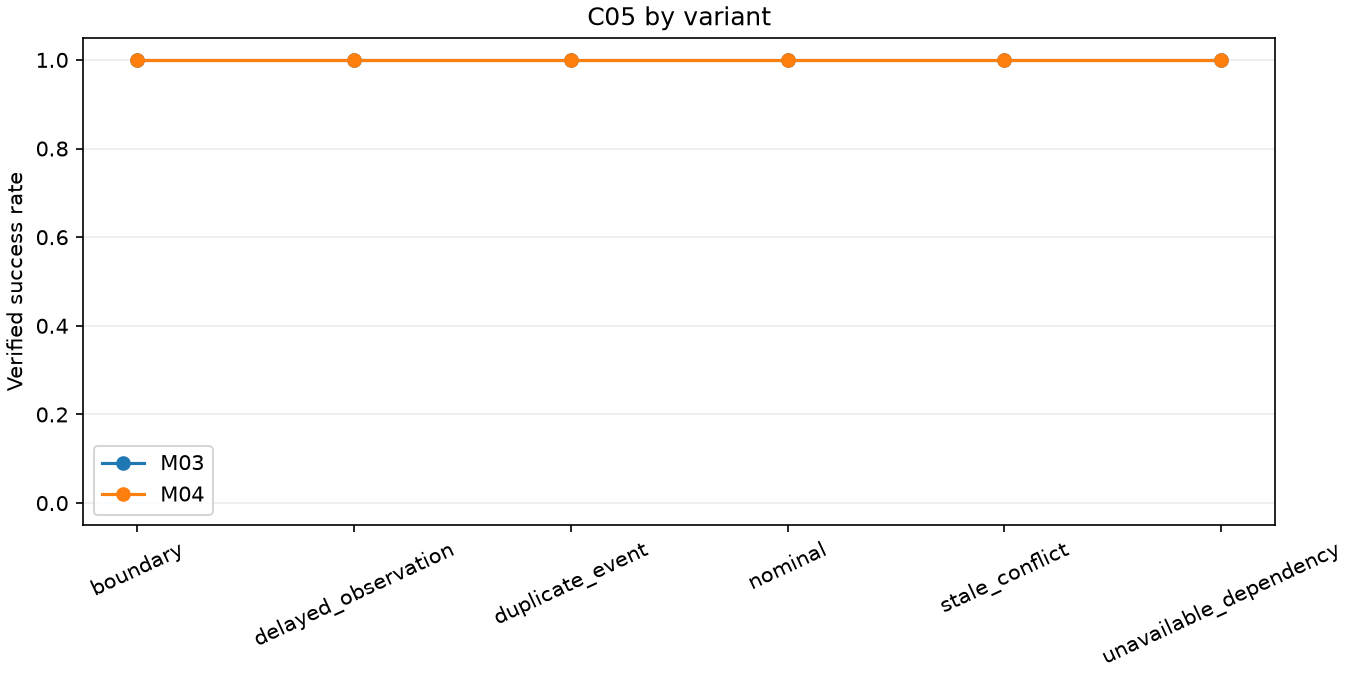

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### learned action scoring · L3 | Build the first executable policy

In level 3, construct policy M03 for learned action scoring with the public factory and keep its observation contract unchanged before sampling C05.

Chart 1, lesson level 3, summarizes learned action ranking and verified outcomes for C05.

In [5]:
# Construct the first released policy through the public factory.
primary_id = 'M03'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M03


### learned action scoring · L3 | Execute the primary method on the named case

In the matched learned action scoring comparison on C05, the learned action scoring evaluator runs M03 on C05 and derives success from the independent task postcondition, not from a replayed trace.

In [6]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### learned action scoring · L3 | Construct an independent comparison policy

Within this learned action scoring comparison (C05), create M04 as a fresh object so recurrent state from M03 cannot leak into the matched comparison.

In [7]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M04'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### learned action scoring · L3 | Run the comparison under identical conditions

This level 3 comparison runs M04 on the same C05, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [8]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### learned action scoring · L3 | Aggregate the two executed episodes

In the matched learned action scoring comparison on C05, the package aggregator summarizes two executed learned action scoring episodes, and cross-family claims still require the complete benchmark below.

In [9]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### learned action scoring · L3 | Fresh policy outcomes

Within this learned action scoring comparison (C05), the next plot is computed from the learned action scoring episode results just executed for C05 rather than copied from a frozen artifact.

## Comparison
Logistic regression and gradient-boosted trees are established supervised methods, while calibration evaluates how scores relate to observed outcomes.

This 02 learned action policies lesson, interprets only its declared software case and seed. For the learned action scoring comparator run on C05, the executed policy's score does not grant authority: For the learned action scoring comparator run on C05, an independent environment check determines whether the requested postcondition was met. In the matched learned action scoring comparison on C05, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. For the learned action scoring comparator run on C05, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. For the learned action scoring comparator run on C05, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; In the matched learned action scoring comparison on C05, failures and cancellations stay in their original denominators. For the learned action scoring comparator run on C05, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. For the learned action scoring comparator run on C05, readers can change the case or seed and observe where the inference stops applying.

For 02 learned action policies begin by distinguishing policy preference from action authority. For the learned action scoring comparator run on C05, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. In this 02 learned action policies example, inspect the episode result together with decision latency; For the learned action scoring comparator run on C05, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. For the learned action scoring comparator run on C05, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. The 02 learned action policies measurements cover the recorded software tasks and their frozen protocol. For the learned action scoring comparator run on C05, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. Within this learned action scoring comparison (C05), use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. This makes the 02 learned action policies exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### learned action scoring · L3 | Execute the XGBoost reference on matched conditions

This level 3 learned action scoring reference call executes M04 on C05 with the same nominal seed as the fresh policies, and its score and time form one matched observation.

In [10]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


This level 3 learned action scoring view describes the recorded environment under its declared case, variant and seed.

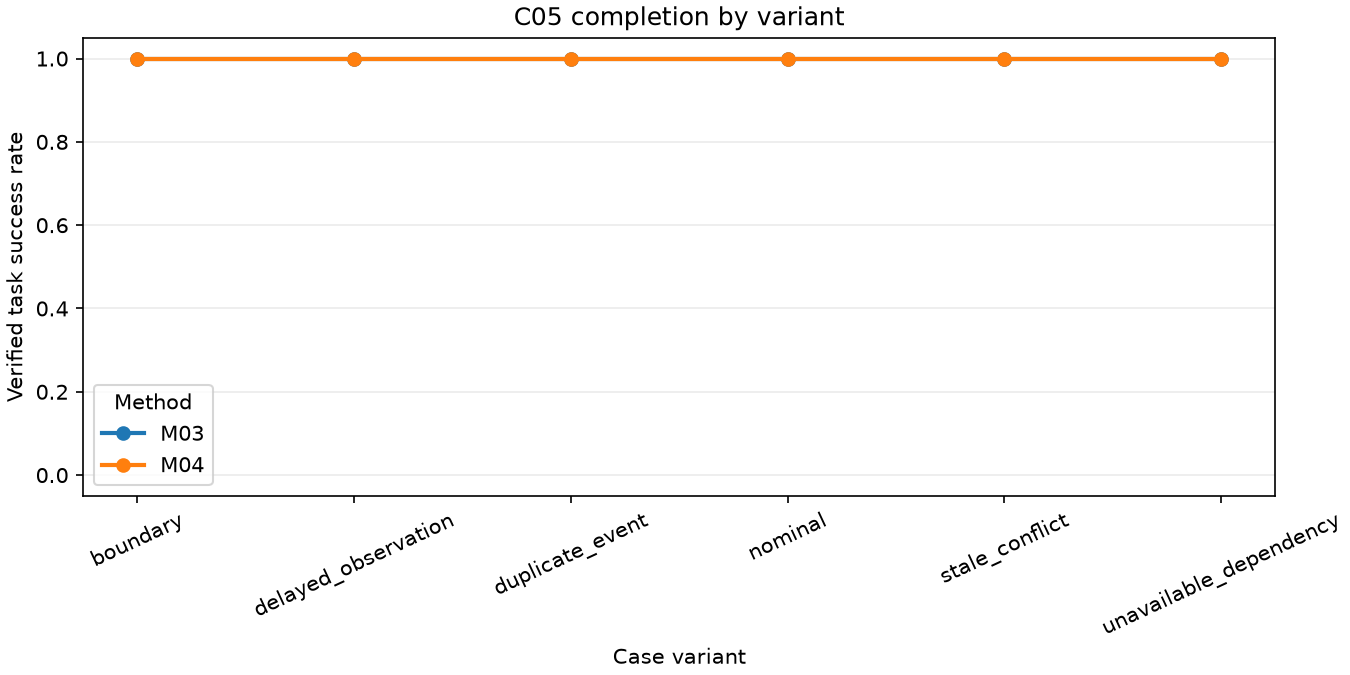

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Within this learned action scoring comparison (C05), for learned action scoring, these bars show fresh task-postcondition outcomes for M03 and M04 on C05, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the matched learned action scoring comparison on C05, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

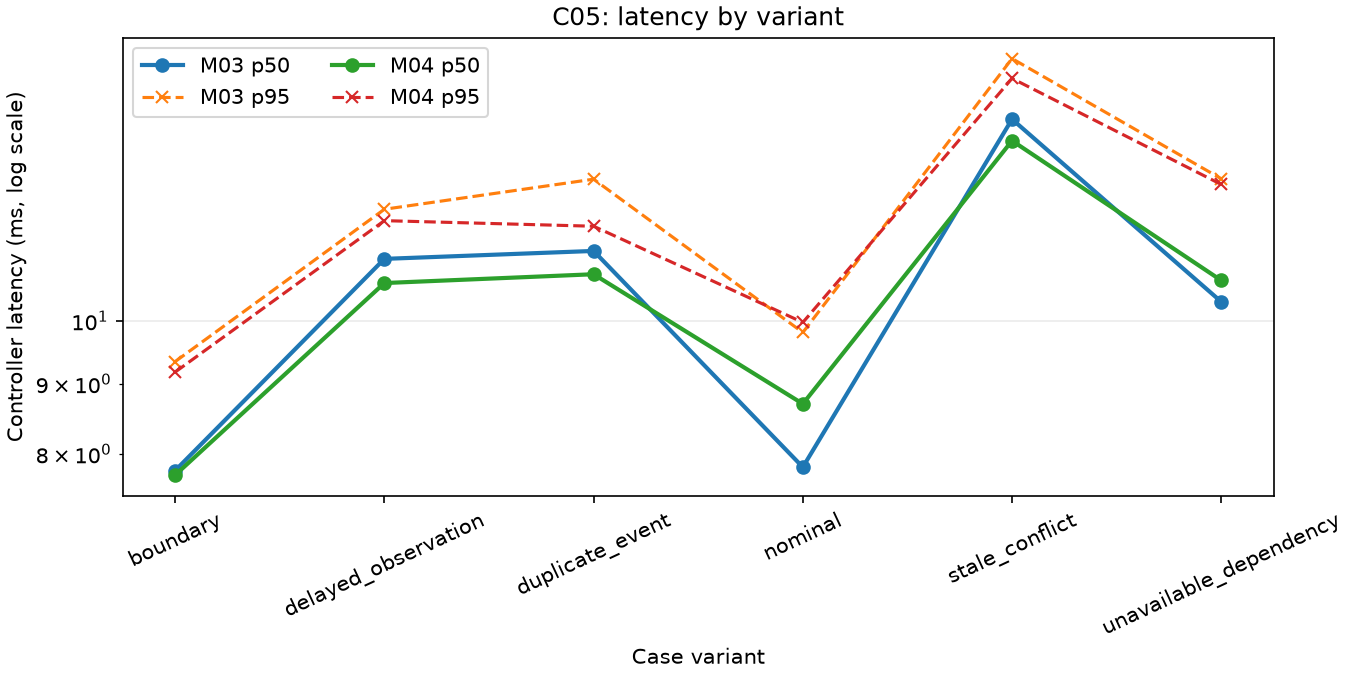

In [12]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Controller latency (ms, log scale)")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + ": latency by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 learned action scoring chart reads canonical M03/M04 records for C05, nominal variant and seed 40000 after the data boundary verifies their hashes.

Chart 3, lesson level 3, summarizes whether action scores change outcomes enough to justify their computation for C05.

## Results

**Answer:** The learned action scoring level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C05; those 3 matched runs do not establish population-level superiority for learned action scoring.

In the matched learned action scoring comparison on C05, the package checkpoints are separately released assets and are not committed The displayed fitted-method outcomes are the hash-verified recorded evaluations, not a freshly refitted model; In the matched learned action scoring comparison on C05, A rate on designed families is not an estimate for arbitrary software tasks;

## Summary

A tie on this case does not establish that learned action scoring generalizes to new compositions.




## References
- [XGB](https://arxiv.org/abs/1603.02754) - [GRU](https://arxiv.org/abs/1406.1078) - [LINUCB](https://arxiv.org/abs/1003.0146)